# BÀI 5 (TRANG 26, 27): PHÂN LỚP DỮ LIỆU HEART DISEASE
- **Sinh viên thực hiện:** Dương Đại Phát
- **MSSV:** 6451071058
- **Nguồn dataset:** Google Drive (`heart.csv`)

In [1]:
print("Dương Đại Phát - 6451071058")
import os
import subprocess
import sys

files_to_download = {
    "heart.csv": "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb",
}
for fname, fid in files_to_download.items():
    if not os.path.exists(fname):
        subprocess.check_call([sys.executable, "-m", "gdown", f"https://drive.google.com/uc?id={fid}", "-O", fname])

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB

Dương Đại Phát - 6451071058


## Câu a): Nhập dữ liệu, xóa dòng dữ liệu trống và đổi tên các cột

In [2]:
print("Dương Đại Phát - 6451071058")
data = pd.read_csv('heart.csv')
print("Kích thước ban đầu:", data.shape)
data = data.replace('?', np.nan).dropna().reset_index(drop=True)

data.columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
    'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
    'exercise_induced_angina', 'st_depression', 'st_slope',
    'num_major_vessels', 'thalassemia', 'target'
]
print("Kích thước sau tiền xử lý:", data.shape)
data.info()
data.head()

Dương Đại Phát - 6451071058
Kích thước ban đầu: (303, 14)
Kích thước sau tiền xử lý: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null  

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng Pearson

Dương Đại Phát - 6451071058


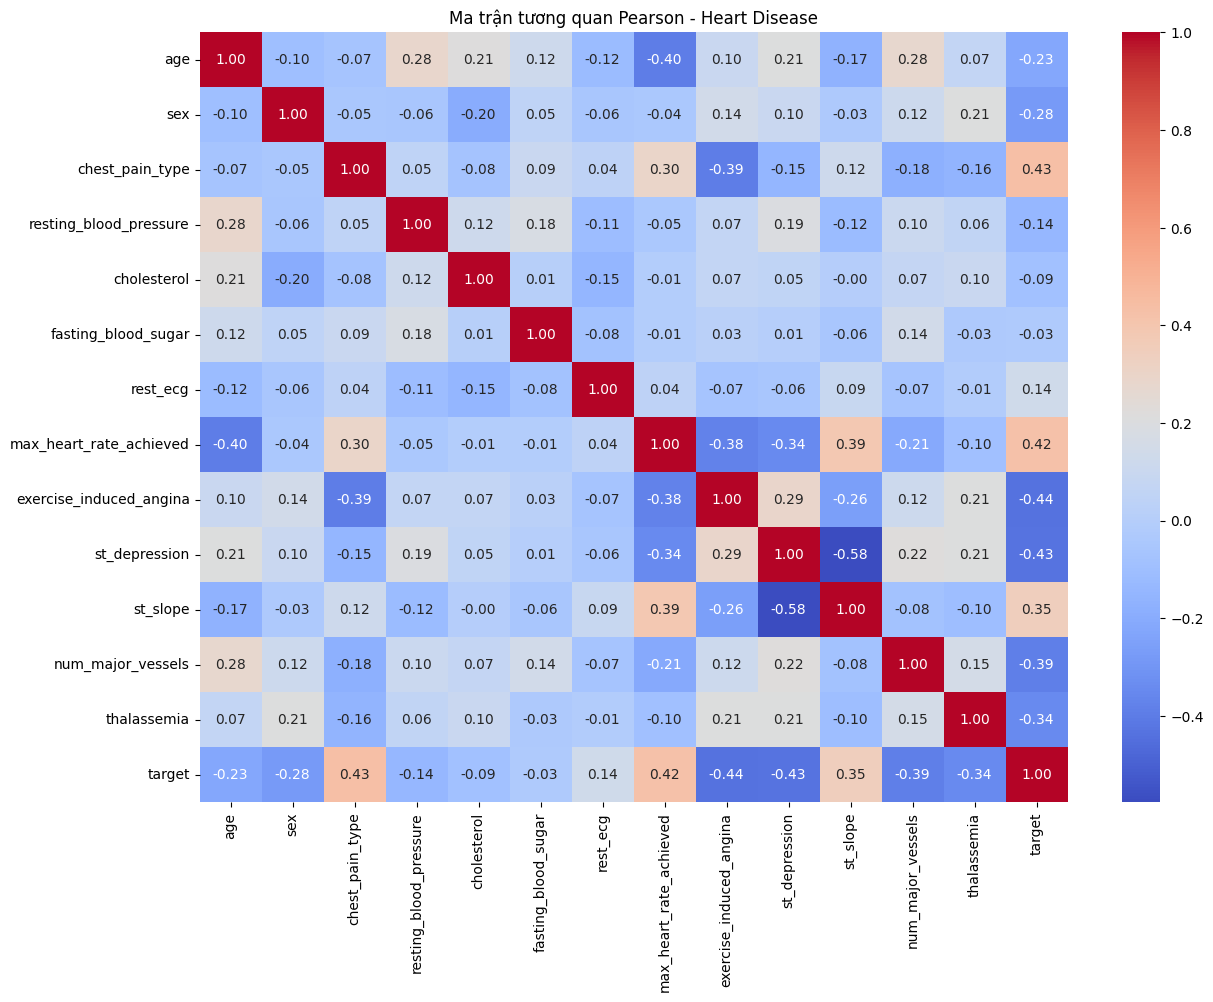

Nhận xét: Cặp tương quan lớn nhất giữa các đặc trưng là st_depression và st_slope (-0.58).
Không có cặp nào có tương quan quá cao (>= 0.8), nên giữ lại tất cả các cột.


In [3]:
print("Dương Đại Phát - 6451071058")
plt.figure(figsize=(14, 10))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Ma trận tương quan Pearson - Heart Disease")
plt.show()

print("Nhận xét: Cặp tương quan lớn nhất giữa các đặc trưng là st_depression và st_slope (-0.58).")
print("Không có cặp nào có tương quan quá cao (>= 0.8), nên giữ lại tất cả các cột.")

## Câu 4: Tách `features` và `labels` (`target`)

In [4]:
print("Dương Đại Phát - 6451071058")
features = data.drop('target', axis=1)
labels = data['target']
print("Features shape:", features.shape)
print("Phân bố nhãn target:\n", labels.value_counts())

Dương Đại Phát - 6451071058
Features shape: (303, 13)
Phân bố nhãn target:
 target
1    165
0    138
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về one-hot vector

In [5]:
print("Dương Đại Phát - 6451071058")
non_numeric_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các cột không phải dạng số:", list(non_numeric_cols))
features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print("Kích thước features_onehot:", features_onehot.shape)
features_onehot.head()

Dương Đại Phát - 6451071058
Các cột không phải dạng số: []
Kích thước features_onehot: (303, 13)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


## Câu 6: Chia dữ liệu thành tập huấn luyện 70% và kiểm thử 30%

In [6]:
print("Dương Đại Phát - 6451071058")
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Dương Đại Phát - 6451071058
X_train: (212, 13) | X_test: (91, 13)


## Câu 7: Xây dựng cây quyết định ID3 (`criterion='entropy'`)

Dương Đại Phát - 6451071058
ID3 Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



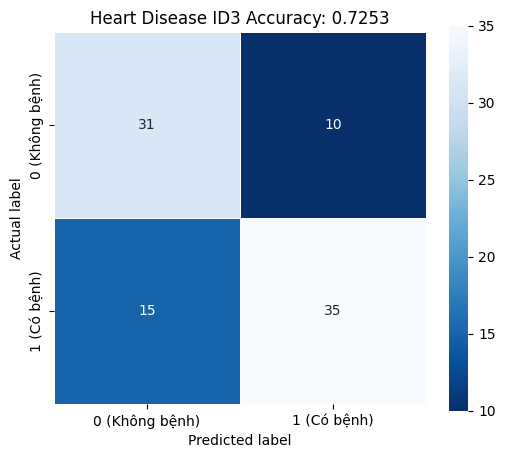

In [7]:
print("Dương Đại Phát - 6451071058")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("ID3 Accuracy:", id3_score)
print("Report:\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=['0 (Không bệnh)', '1 (Có bệnh)'], yticklabels=['0 (Không bệnh)', '1 (Có bệnh)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Heart Disease ID3 Accuracy: {id3_score:.4f}', size=12)
plt.show()

Dương Đại Phát - 6451071058


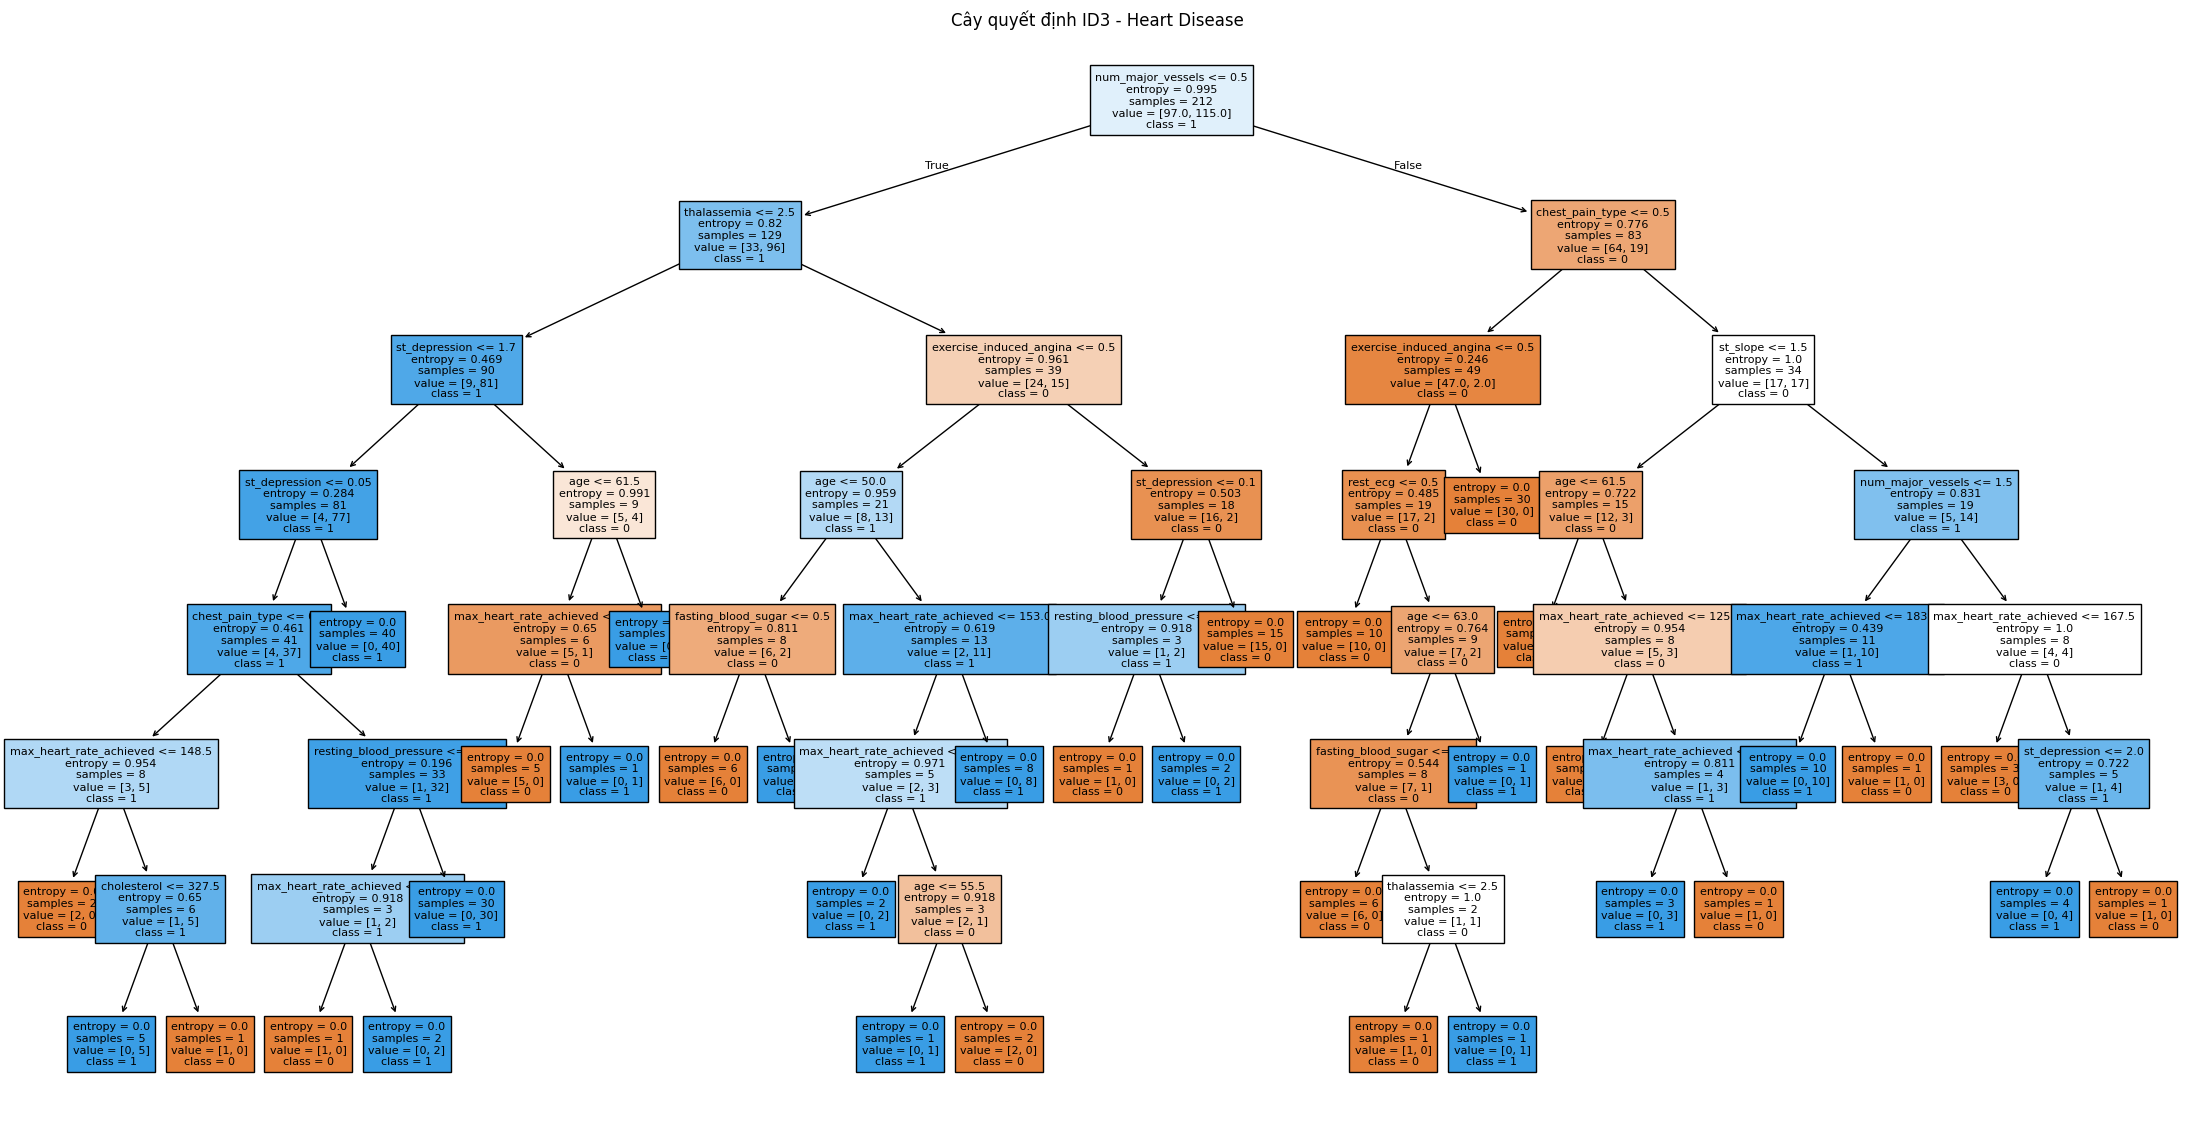

In [8]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(28, 14))
tree.plot_tree(clf_id3, filled=True, fontsize=8,
               feature_names=features_onehot.columns, class_names=['0', '1'])
plt.title("Cây quyết định ID3 - Heart Disease")
plt.savefig('heart_tree_id3.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 8: Xây dựng cây quyết định CART (`criterion='gini'`)

Dương Đại Phát - 6451071058
CART Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



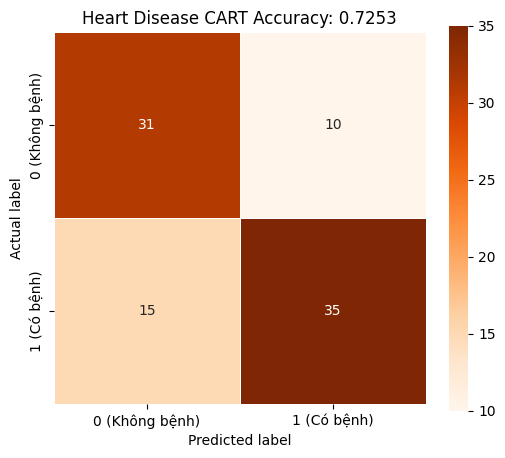

In [9]:
print("Dương Đại Phát - 6451071058")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("CART Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Oranges',
            xticklabels=['0 (Không bệnh)', '1 (Có bệnh)'], yticklabels=['0 (Không bệnh)', '1 (Có bệnh)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Heart Disease CART Accuracy: {cart_score:.4f}', size=12)
plt.show()

Dương Đại Phát - 6451071058


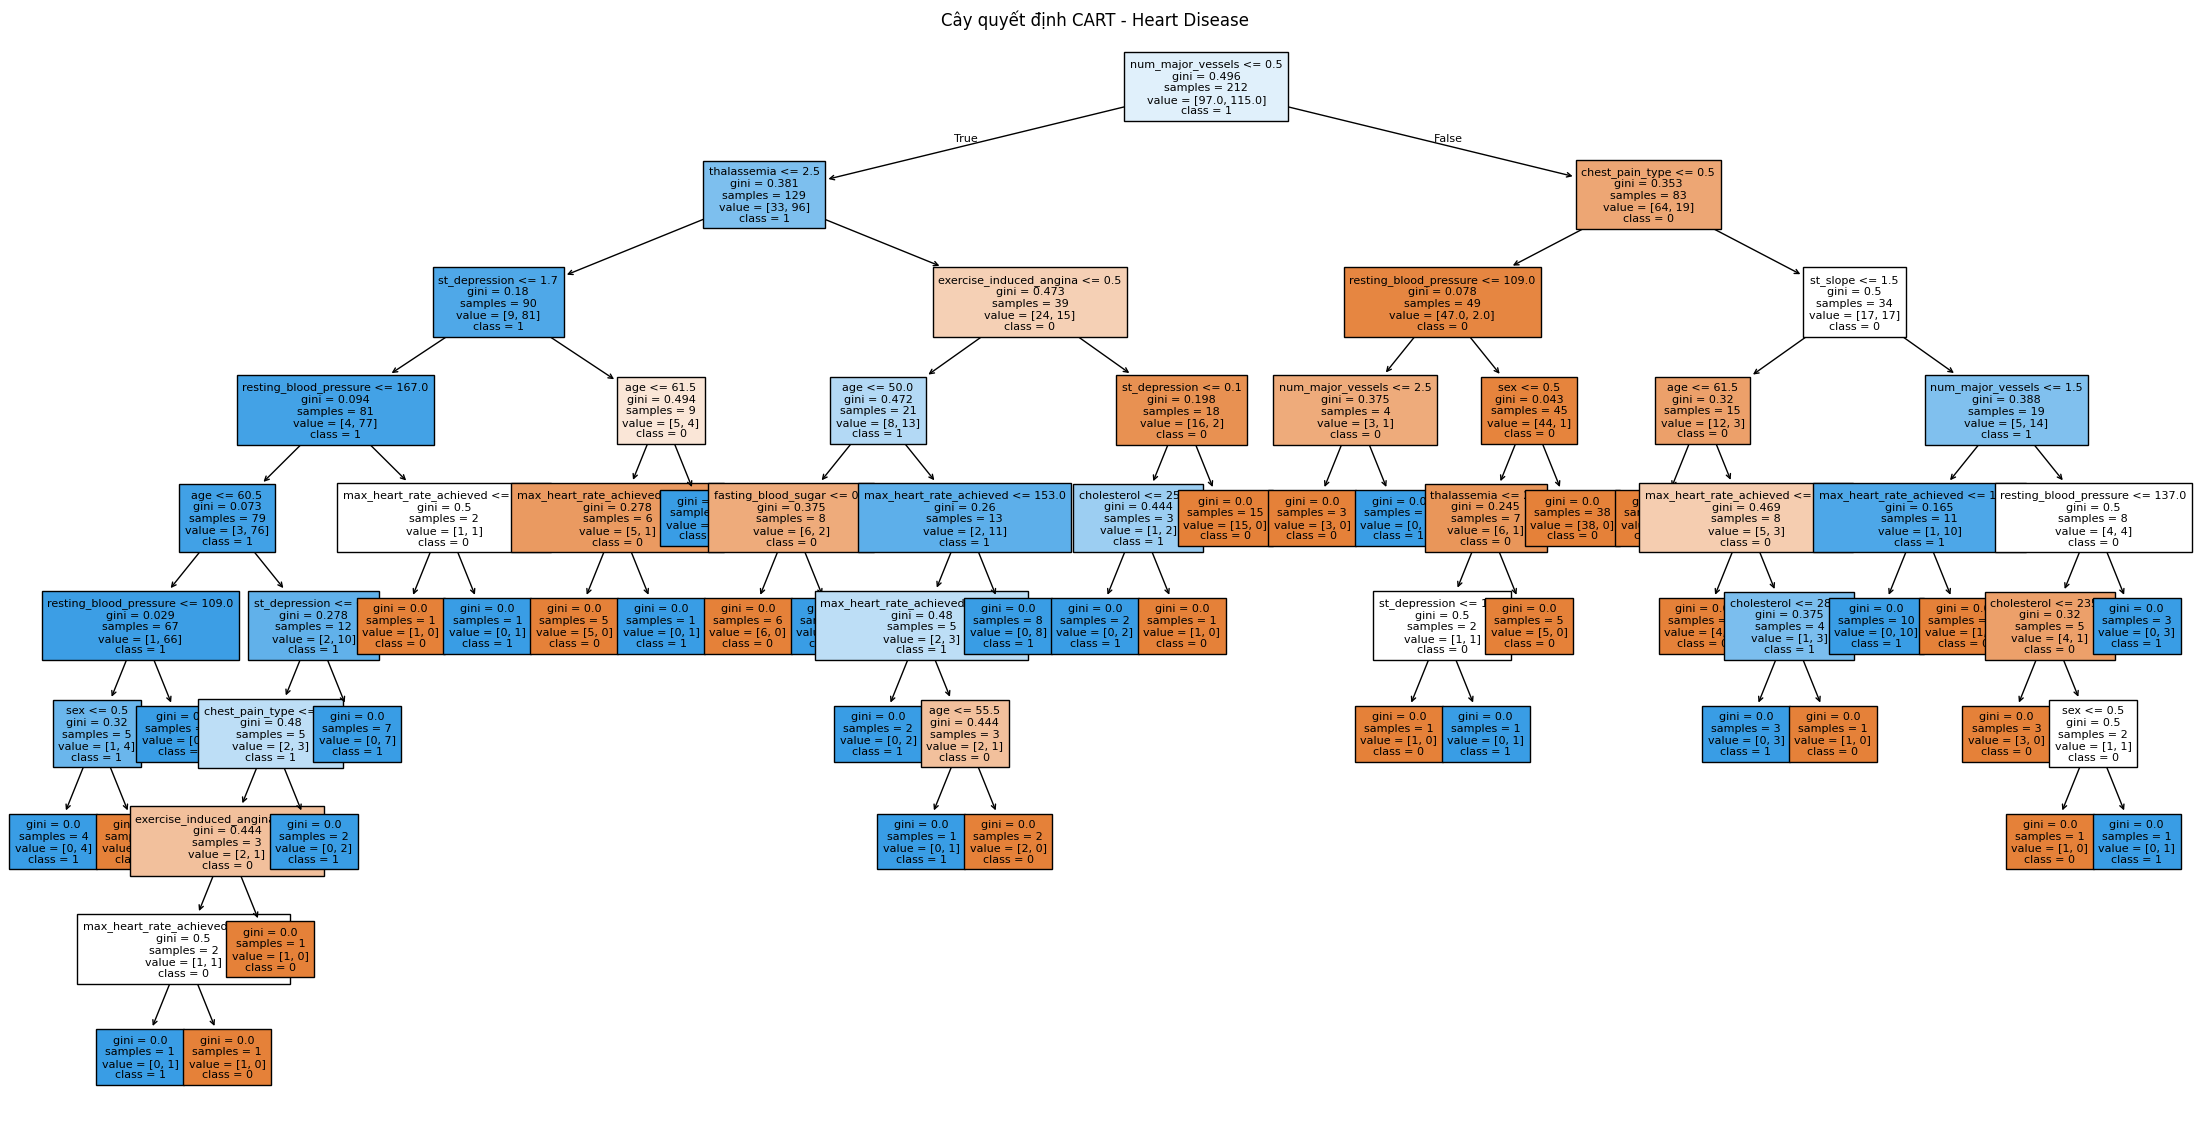

In [10]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(28, 14))
tree.plot_tree(clf_cart, filled=True, fontsize=8,
               feature_names=features_onehot.columns, class_names=['0', '1'])
plt.title("Cây quyết định CART - Heart Disease")
plt.savefig('heart_tree_cart.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`)

Dương Đại Phát - 6451071058
Naive Bayes Accuracy: 0.8351648351648352
Report:
               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



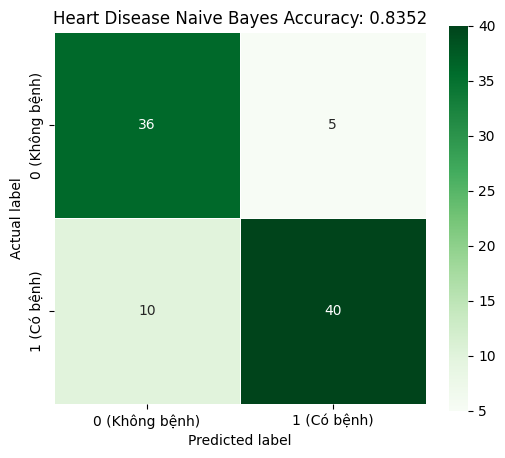

In [11]:
print("Dương Đại Phát - 6451071058")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Naive Bayes Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=['0 (Không bệnh)', '1 (Có bệnh)'], yticklabels=['0 (Không bệnh)', '1 (Có bệnh)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Heart Disease Naive Bayes Accuracy: {bayes_score:.4f}', size=12)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

In [12]:
print("Dương Đại Phát - 6451071058")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naive Bayes", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": round(metrics.accuracy_score(y_test, pred), 4),
        "Precision (Macro)": round(metrics.precision_score(y_test, pred, average='macro'), 4),
        "Recall (Macro)": round(metrics.recall_score(y_test, pred, average='macro'), 4),
        "F1-score (Macro)": round(metrics.f1_score(y_test, pred, average='macro'), 4),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))
print("\nNhận xét: Trên tập Heart Disease (kích thước vừa phải 303 dòng), Naive Bayes đạt kết quả cao hơn rõ rệt so với cây quyết định ID3 và CART (vốn dễ bị overfitting khi cây không cắt tỉa trên tập dữ liệu nhỏ).")

Dương Đại Phát - 6451071058
      Mô hình  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
ID3 (Entropy)    0.7253             0.7258           0.728            0.7247
  CART (Gini)    0.7253             0.7258           0.728            0.7247
  Naive Bayes    0.8352             0.8357           0.839            0.8348

Nhận xét: Trên tập Heart Disease (kích thước vừa phải 303 dòng), Naive Bayes đạt kết quả cao hơn rõ rệt so với cây quyết định ID3 và CART (vốn dễ bị overfitting khi cây không cắt tỉa trên tập dữ liệu nhỏ).
